In [ ]:
# Data Loading and Initial Exploration for Clustering Analysis
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/Datasets/DataJobID-2982251_2982251_UAEtrade.csv', encoding='latin1')
print(df.shape)
print(df.dtypes)
print(df.isna().sum())

(3456, 10)
ReporterISO3               object
ProductCode                 int64
ReporterName               object
PartnerISO3                object
PartnerName                object
Year                        int64
TradeFlowName              object
TradeFlowCode               int64
TradeValue in 1000 USD    float64
ProductDescription         object
dtype: object
ReporterISO3              0
ProductCode               0
ReporterName              0
PartnerISO3               0
PartnerName               0
Year                      0
TradeFlowName             0
TradeFlowCode             0
TradeValue in 1000 USD    0
ProductDescription        0
dtype: int64


In [ ]:
# Data Pivoting for Clustering Analysis
import numpy as np

# Separate Import / Export / Re-Export as columns at (ProductCode, Year)
pivot_df = (
    df.pivot_table(index=['ProductCode','Year','ProductDescription'],
                   columns='TradeFlowName',
                   values='TradeValue in 1000 USD',
                   aggfunc='sum',
                   fill_value=0)
      .reset_index()
)
pivot_df.columns.name = None
pivot_df = pivot_df.sort_values(['ProductCode','Year']).reset_index(drop=True)
print(pivot_df.head())
print(pivot_df.shape)

   ProductCode  Year ProductDescription     Export      Import   Re-Export
0            1  2012       LIVE ANIMALS  15026.289  176010.173   30884.388
1            1  2013       LIVE ANIMALS  26848.269  238531.204   32789.774
2            1  2014       LIVE ANIMALS  32484.459  269308.767  326729.260
3            1  2015       LIVE ANIMALS  36823.115  288170.169   20541.006
4            1  2016       LIVE ANIMALS  27364.859  204225.572   18722.425
(1152, 6)


In [ ]:
# Feature Engineering for Clustering Analysis (Warning-Free Version)
import pandas as pd
import numpy as np

# Data pivoting
pivot_df = (
    df.pivot_table(index=['ProductCode','Year','ProductDescription'],
                   columns='TradeFlowName',
                   values='TradeValue in 1000 USD',
                   aggfunc='sum',
                   fill_value=0)
      .reset_index()
)
pivot_df.columns.name = None

print("Pivoted columns:", pivot_df.columns.tolist())

# Feature engineering functions
EPS = 1e-9

def f_cagr(g):
    g = g.sort_values('Year')
    y = g['Export'].to_numpy()
    if y.size > 1 and (y[0] + EPS) > 0:
        years = y.size - 1
        return float((( (y[-1]+EPS)/(y[0]+EPS) )**(1/years) - 1) * 100)
    return 0.0

def f_consistency(g):
    g = g.sort_values('Year')
    y = g['Export'].to_numpy()
    if y.size > 2:
        gr = []
        for i in range(1, y.size):
            if (y[i-1] + EPS) > 0:
                gr.append(((y[i]-y[i-1])/(y[i-1]+EPS))*100)
        if gr:
            sd = np.std(gr, ddof=1)
            return float(np.clip(100 - min(sd, 100), 0, 100))
    return 50.0

def f_volatility(g):
    y = g['Export'].to_numpy()
    m = y.mean()
    if m > 0:
        return float(min(y.std(ddof=1)/m*100, 1000))
    return 0.0

def f_slope(g):
    g = g.sort_values('Year')
    y = g['Export'].to_numpy()
    if y.size > 1:
        x = np.arange(y.size, dtype=float)
        slope = np.polyfit(x, y, 1)[0]
        m = y.mean()
        if m > 0:
            return float((slope/m)*100)
    return 0.0

def f_rex(g):
    tot = (g['Export'] + g['Re-Export']).to_numpy()
    rex = g['Re-Export'].to_numpy()
    mask = tot > 0
    if mask.any():
        return float(np.mean((rex[mask]/tot[mask])*100))
    return 0.0

def f_size(g):
    avg_export = g['Export'].mean()
    if avg_export < 100_000:
        return 1
    elif avg_export < 1_000_000:
        return 2
    else:
        return 3

# Build feature table
base = pivot_df[['ProductCode','ProductDescription']].drop_duplicates().copy()

# --- Updated warning-free groupby calls ---
fe1 = pivot_df[['ProductCode','Year','Export']]\
    .groupby('ProductCode', group_keys=False)\
    .apply(f_cagr, include_groups=False)\
    .reset_index(name='Export_Growth_Rate')

fe2 = pivot_df[['ProductCode','Year','Export']]\
    .groupby('ProductCode', group_keys=False)\
    .apply(f_consistency, include_groups=False)\
    .reset_index(name='Growth_Consistency')

fe3 = pivot_df[['ProductCode','Export']]\
    .groupby('ProductCode', group_keys=False)\
    .apply(f_volatility, include_groups=False)\
    .reset_index(name='Export_Volatility')

fe4 = pivot_df[['ProductCode','Year','Export']]\
    .groupby('ProductCode', group_keys=False)\
    .apply(f_slope, include_groups=False)\
    .reset_index(name='Trend_Slope')

fe5 = pivot_df[['ProductCode','Export','Re-Export']]\
    .groupby('ProductCode', group_keys=False)\
    .apply(f_rex, include_groups=False)\
    .reset_index(name='Reexport_Dependency')

fe6 = pivot_df[['ProductCode','Export']]\
    .groupby('ProductCode', group_keys=False)\
    .apply(f_size, include_groups=False)\
    .reset_index(name='Trade_Size_Score')

# Merge all features
features = (base
    .merge(fe1, on='ProductCode', how='left')
    .merge(fe2, on='ProductCode', how='left')
    .merge(fe3, on='ProductCode', how='left')
    .merge(fe4, on='ProductCode', how='left')
    .merge(fe5, on='ProductCode', how='left')
    .merge(fe6, on='ProductCode', how='left')
)

# Save features for clustering analysis
features.to_csv('UAE_Growth_Features.csv', index=False)

# Display results
pd.set_option('display.width', 1000)
pd.set_option('display.max_columns', None)

print("\nFIRST 10 ROWS:")
print(features.head(10).to_string(index=False))

print("\nFEATURES DESCRIPTION:")
print(features.describe().to_string())


Pivoted columns: ['ProductCode', 'Year', 'ProductDescription', 'Export', 'Import', 'Re-Export']

FIRST 10 ROWS:
 ProductCode                  ProductDescription  Export_Growth_Rate  Growth_Consistency  Export_Volatility  Trend_Slope  Reexport_Dependency  Trade_Size_Score
           1                        LIVE ANIMALS           17.241643           40.503317          56.029045     8.139055            49.385623                 1
           2          MEAT AND EDIBLE MEAT OFFAL           25.820168           20.469810          84.594149    18.999955            76.596001                 1
           3 FISH AND CRUSTACEANS, MOLLUSCS AND            -0.821510           32.680025          36.255155     1.010301            32.842160                 1
           4 DAIRY PRODUCE; BIRDS' EGGS; NATURAL            4.603990           62.664373          27.423206     4.867274            40.917455                 2
           5 PRODUCTS OF ANIMAL ORIGIN, NOT ELSE           16.592129            0.000000

<Figure size 1500x1200 with 0 Axes>

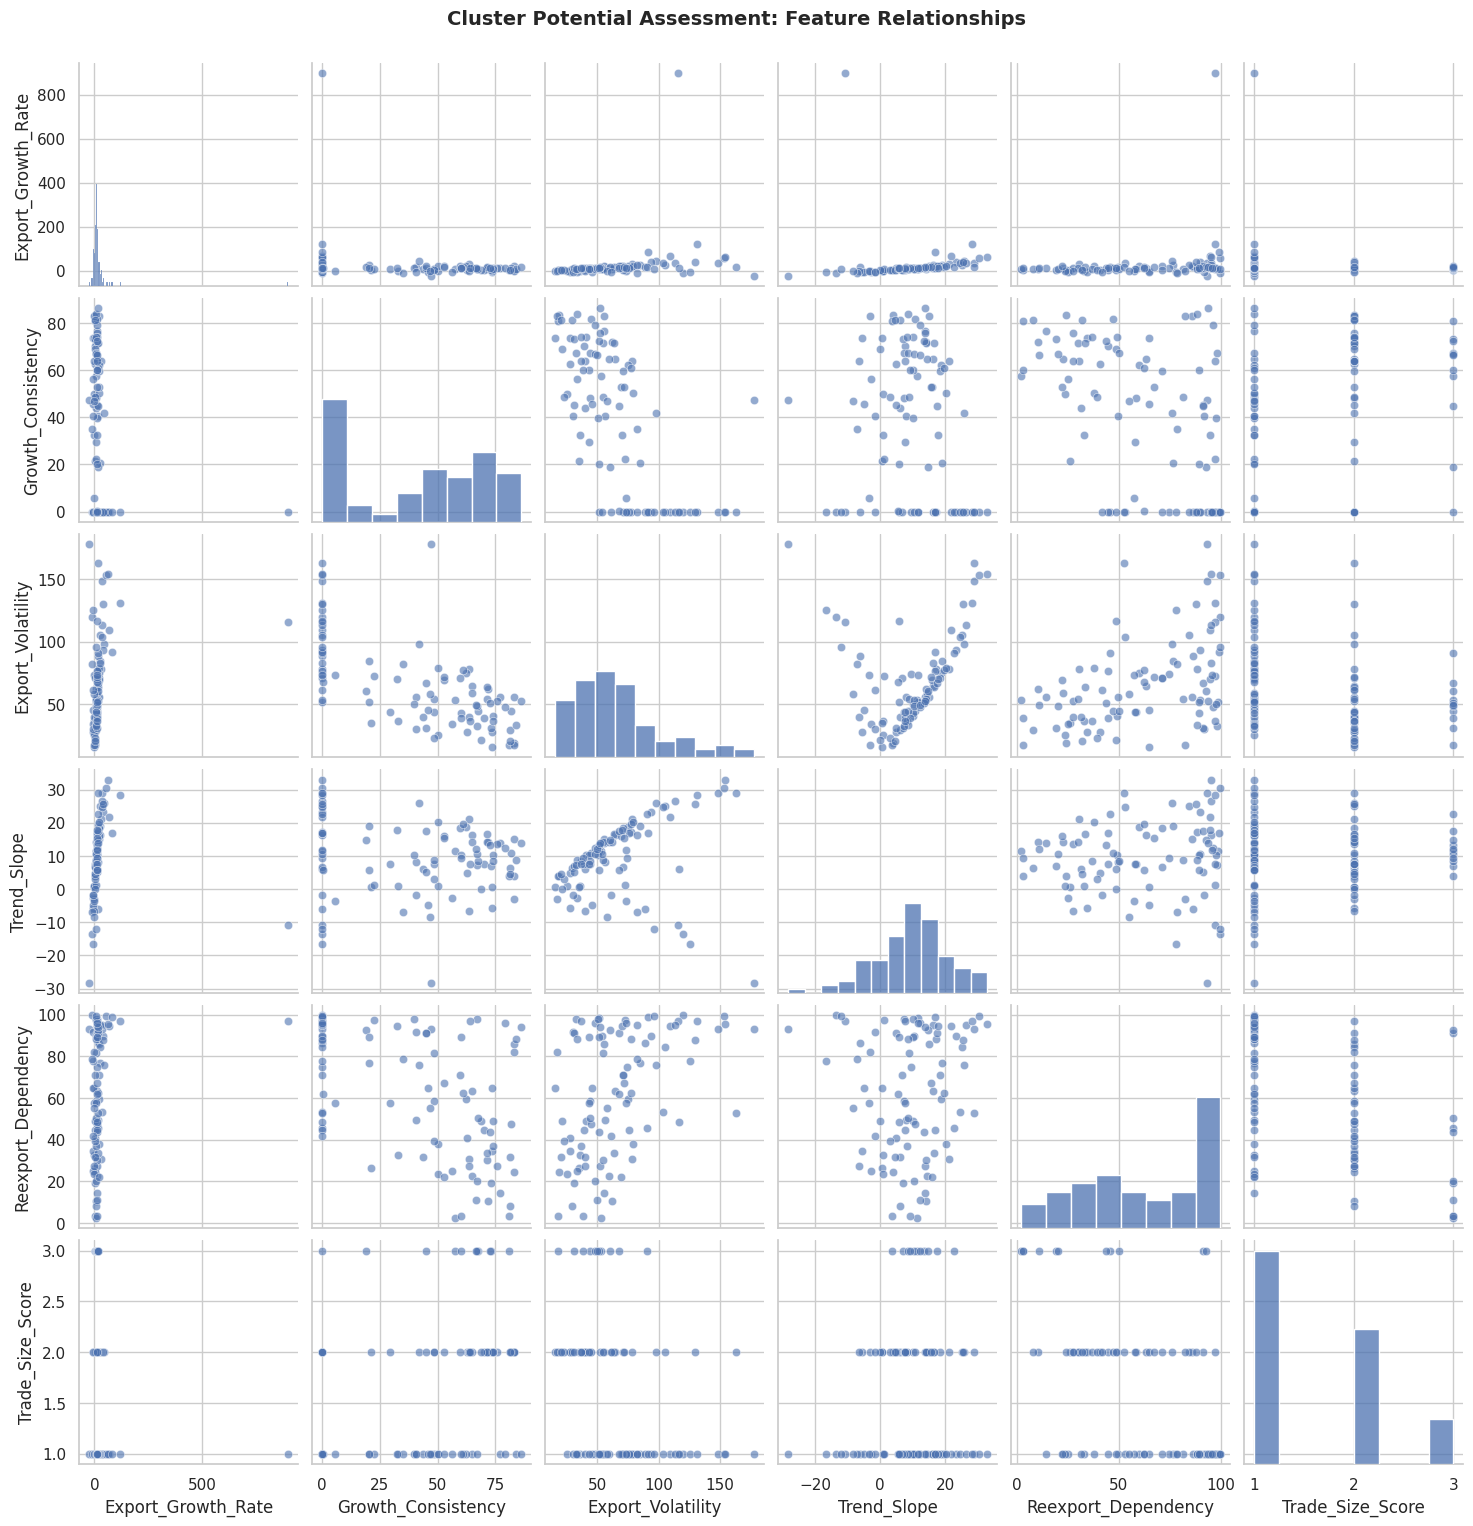

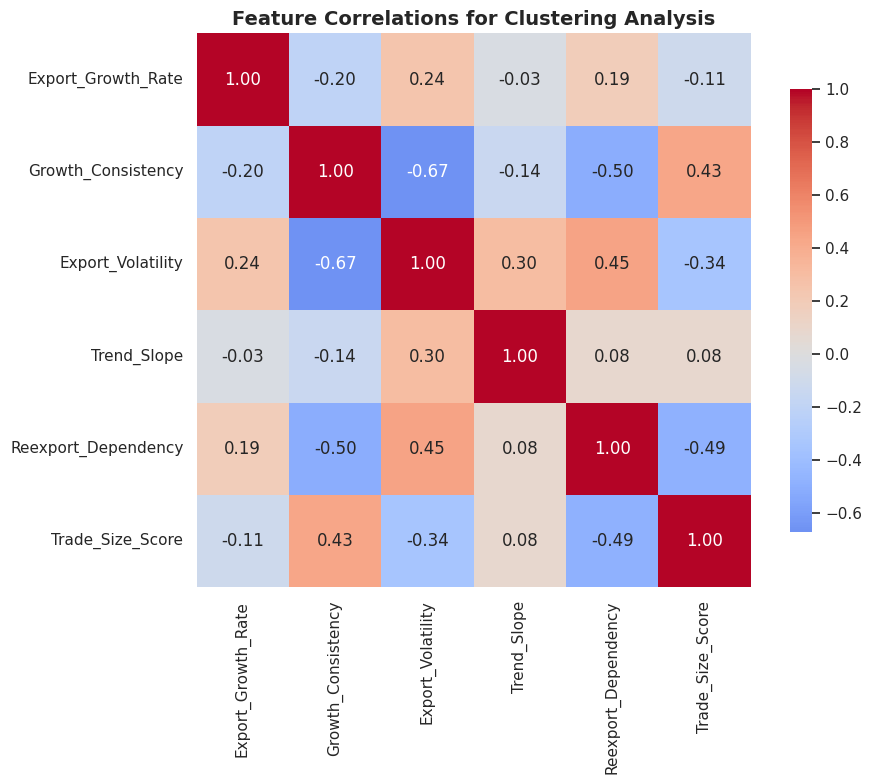

In [ ]:
# Clustering Pre-analysis: Pairplot Visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load features data
clustering_df = pd.read_csv('/content/UAE_Growth_Features.csv')

# Select features for clustering
feature_columns = [
    'Export_Growth_Rate',
    'Growth_Consistency',
    'Export_Volatility',
    'Trend_Slope',
    'Reexport_Dependency',
    'Trade_Size_Score'
]

# Pairplot visualization with histograms (bar charts)
sns.set(style='whitegrid')
plt.figure(figsize=(15, 12))

pairplot = sns.pairplot(
    clustering_df,
    vars=feature_columns,
    diag_kind='hist',  # Use histograms instead of KDE
    plot_kws={'alpha': 0.6}
)

plt.suptitle('Cluster Potential Assessment: Feature Relationships',
             y=1.02, fontsize=14, fontweight='bold')
plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 8))
correlation_matrix = clustering_df[feature_columns].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    center=0,
    square=True,
    fmt='.2f',
    cbar_kws={'shrink': 0.8}
)

plt.title('Feature Correlations for Clustering Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

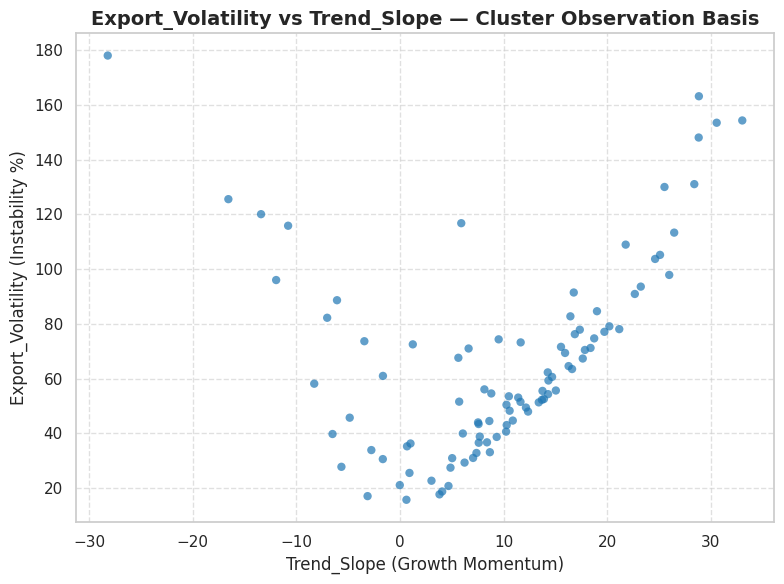

In [ ]:
# Scatter Plot for Cluster Observation
import pandas as pd
import matplotlib.pyplot as plt

# Load features dataset
clustering_features = pd.read_csv('UAE_Growth_Features.csv')

# Create scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(
    clustering_features["Trend_Slope"],
    clustering_features["Export_Volatility"],
    color="#1f77b4",  # light blue
    alpha=0.7,
    edgecolors="none"
)
plt.xlabel("Trend_Slope (Growth Momentum)", fontsize=12)
plt.ylabel("Export_Volatility (Instability %)", fontsize=12)
plt.title("Export_Volatility vs Trend_Slope — Cluster Observation Basis", fontsize=14, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


In [ ]:
# Creating a dataframe "x" with the columns "Trend_Slope" and "Export_Volatility"
x = clustering_features[["Trend_Slope", "Export_Volatility"]]
x.head()

,Trend_Slope,Export_Volatility
0,8.139055,56.029045
1,18.999955,84.594149
2,1.010301,36.255155
3,4.867274,27.423206
4,-6.080298,88.609714


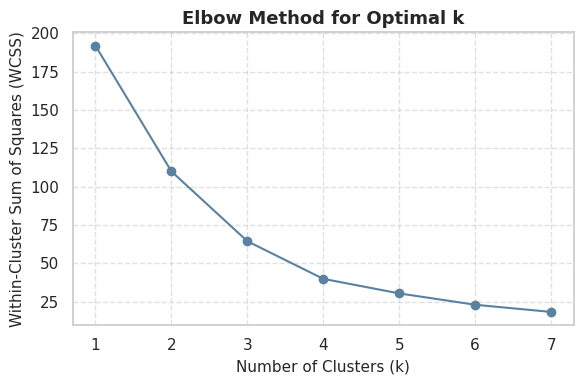

In [ ]:
# Elbow Method for Optimal Clusters
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Select and standardize features
x = clustering_features[["Trend_Slope", "Export_Volatility"]].copy()
scaler = StandardScaler()
Xs = scaler.fit_transform(x)

# Compute WCSS for k = 1 to 7
wcss = []
for k in range(1, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    km.fit(Xs)
    wcss.append(km.inertia_)

# Plot Elbow curve with darker blue
plt.figure(figsize=(6, 4))
plt.plot(
    range(1, 8),
    wcss,
    marker='o',
    linestyle='-',
    color='#5a82a0'  # darker blue
)
plt.title('Elbow Method for Optimal k', fontsize=13, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=11)
plt.ylabel('Within-Cluster Sum of Squares (WCSS)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


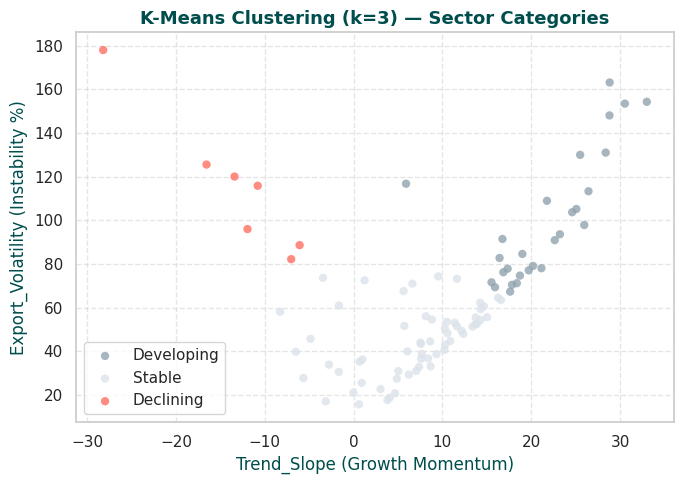

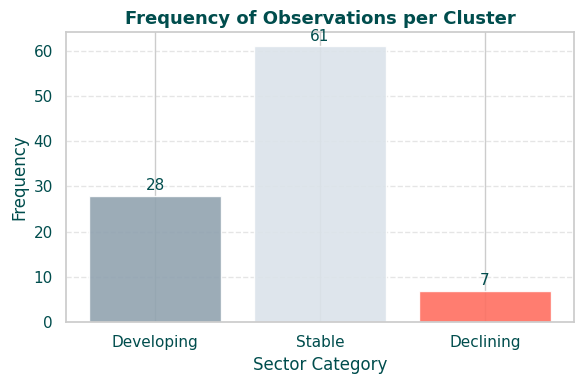

In [ ]:
import matplotlib.pyplot as plt

# Custom color scheme (preferred palette)
cluster_colors = {
    'Developing': '#91A3B0',   # Gray Azure
    'Stable':     '#dbe3ea',   # Grayish Blue
    'Declining':  '#FF6F61'    # Coral accent
}

# --- Scatter Plot (Clusters by Trend_Slope vs Export_Volatility) ---
plt.figure(figsize=(7, 5))
for cluster_name in cluster_colors.keys():
    subset = data_with_clusters[data_with_clusters['Cluster_Name'] == cluster_name]
    plt.scatter(
        subset['Trend_Slope'],
        subset['Export_Volatility'],
        color=cluster_colors[cluster_name],
        alpha=0.8,
        edgecolors='none',
        label=cluster_name
    )

plt.xlabel('Trend_Slope (Growth Momentum)', fontsize=12, color='#004d4d')
plt.ylabel('Export_Volatility (Instability %)', fontsize=12, color='#004d4d')
plt.title('K-Means Clustering (k=3) — Sector Categories', fontsize=13, fontweight='bold', color='#004d4d')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# --- Bar Chart (Cluster Frequencies) ---
cluster_counts = data_with_clusters['Cluster_Name'].value_counts().reindex(['Developing','Stable','Declining'])

plt.figure(figsize=(6, 4))
bars = plt.bar(
    cluster_counts.index,
    cluster_counts.values,
    color=[cluster_colors[name] for name in cluster_counts.index],
    alpha=0.9
)

# Add labels above bars
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.5,
             f"{int(bar.get_height())}",
             ha='center', va='bottom', fontsize=11, color='#004d4d')

plt.xlabel('Sector Category', fontsize=12, color='#004d4d')
plt.ylabel('Frequency', fontsize=12, color='#004d4d')
plt.title('Frequency of Observations per Cluster', fontsize=13, fontweight='bold', color='#004d4d')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(color='#004d4d')
plt.yticks(color='#004d4d')
plt.gca().set_facecolor('white')
plt.tight_layout()
plt.show()


In [ ]:
# Reset index to effectively "hide" it
sil_scores_df_reset = sil_scores_df.reset_index(drop=True)

# Style the table
styled_table = sil_scores_df_reset.style.set_table_styles([
    {'selector': 'thead th', 'props': [('background-color', '#91A3B0'), ('color', 'white'), ('font-weight', 'bold')]},
    {'selector': 'tbody td', 'props': [('background-color', '#dbe3ea'), ('color', '#004d4d')]},
    {'selector': 'tbody tr:hover', 'props': [('background-color', '#FF6F61'), ('color', 'white')]}
]).set_properties(**{'text-align': 'center'})

styled_table


,Clustering Method,Silhouette Score
0,KMeans,0.497000
1,DBSCAN,nan
2,Agglomerative,0.494000
3,GMM,0.310000


Clusters: 1
Noise points: 2


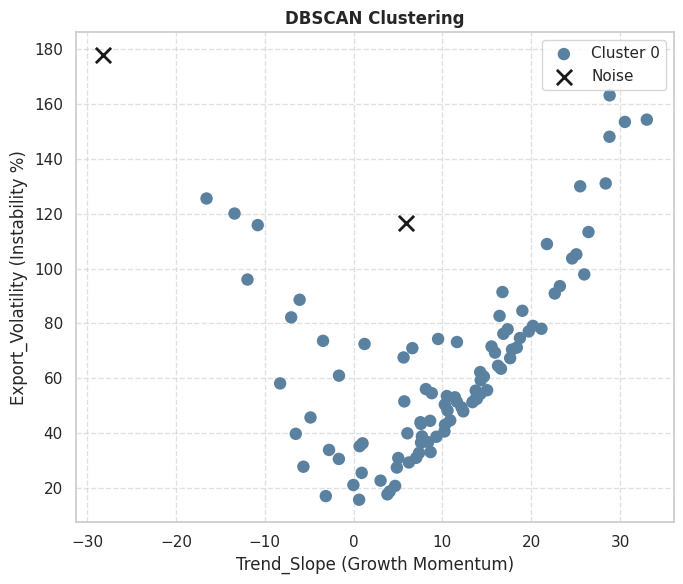

In [ ]:
# DBSCAN Clustering Implementation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Select features
X = clustering_features[["Trend_Slope", "Export_Volatility"]].copy()

# Standardize features
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

# DBSCAN parameters
eps = 0.9
min_samples = 3

# Fit DBSCAN
db = DBSCAN(eps=eps, min_samples=min_samples, metric='euclidean')
labels = db.fit_predict(Xs)

# Attach labels
data_dbscan = X.copy()
data_dbscan["DBSCAN_Cluster"] = labels

# Count clusters and noise
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int((labels == -1).sum())
print(f"Clusters: {n_clusters}")
print(f"Noise points: {n_noise}")

# Silhouette score (non-noise only)
mask = labels != -1
if n_clusters > 1 and mask.sum() > n_clusters:
    sil = silhouette_score(Xs[mask], labels[mask])
    print(f"Silhouette Score: {sil:.3f}")

# Define darker color scheme for clusters
cluster_colors = {0: '#5a82a0', 1: '#7ab36e', 2: '#e6a15f'}  # blue, green, coral

# Scatter plot
plt.figure(figsize=(7,6))
noise_mask = labels == -1

# Plot clusters with specific colors
for cluster_label in set(labels):
    if cluster_label == -1:
        continue
    cluster_mask = labels == cluster_label
    plt.scatter(
        data_dbscan.loc[cluster_mask, "Trend_Slope"],
        data_dbscan.loc[cluster_mask, "Export_Volatility"],
        color=cluster_colors.get(cluster_label, '#5a82a0'),
        s=80,
        edgecolors='none',
        label=f'Cluster {cluster_label}'
    )

# Plot noise points
plt.scatter(
    data_dbscan.loc[noise_mask, "Trend_Slope"],
    data_dbscan.loc[noise_mask, "Export_Volatility"],
    marker='x', s=120, linewidths=2, color='k', label='Noise'
)

plt.xlabel("Trend_Slope (Growth Momentum)")
plt.ylabel("Export_Volatility (Instability %)")
plt.title("DBSCAN Clustering", fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


Silhouette Score: 0.497

CLUSTER COUNTS:
Cluster_Label
Stable        61
Developing    28
Declining      7
Name: count, dtype: int64

CLUSTER MEANS:
                       Trend_Slope  Export_Volatility  Export_Growth_Rate
Cluster Cluster_Label                                                    
0       Developing           21.51              99.34               33.74
1       Stable                6.73              44.95                6.72
2       Declining           -13.43             115.17              125.00


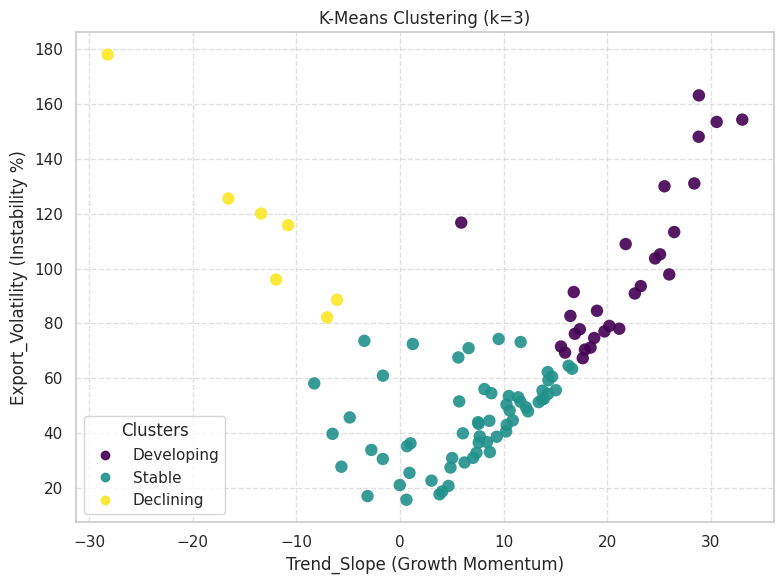

In [ ]:
# K-Means Clustering with Sector Labels
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Select features and standardize
X = clustering_features[["Trend_Slope", "Export_Volatility"]].copy()
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

# Fit K-Means (k=3)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=20)
labels_km = kmeans.fit_predict(Xs)

# Build results table
res = clustering_features[[
    "ProductCode","ProductDescription",
    "Export_Growth_Rate","Trend_Slope","Export_Volatility"
]].copy()
res["Cluster"] = labels_km

# Compute cluster means
means = res.groupby("Cluster")[["Trend_Slope","Export_Volatility","Export_Growth_Rate"]].mean()

# Map to research labels by growth momentum
order = means.sort_values("Trend_Slope").index.tolist()
label_map = {
    order[0]: "Declining",
    order[1]: "Stable",
    order[2]: "Developing"
}
res["Cluster_Label"] = res["Cluster"].map(label_map)

# Quality metric
sil = silhouette_score(Xs, labels_km)
print(f"Silhouette Score: {sil:.3f}")

print("\nCLUSTER COUNTS:")
print(res["Cluster_Label"].value_counts())

print("\nCLUSTER MEANS:")
print(res.groupby(["Cluster","Cluster_Label"])[
    ["Trend_Slope","Export_Volatility","Export_Growth_Rate"]
].mean().round(2))

# Plot clusters
plt.figure(figsize=(8,6))
scatter = plt.scatter(
    res["Trend_Slope"], res["Export_Volatility"],
    c=res["Cluster"], cmap="viridis", s=80, alpha=0.9, edgecolors="none"
)
handles, _ = scatter.legend_elements()
legend_labels = [label_map[i] for i in sorted(res["Cluster"].unique())]
plt.legend(handles, legend_labels, title="Clusters")
plt.xlabel("Trend_Slope (Growth Momentum)")
plt.ylabel("Export_Volatility (Instability %)")
plt.title("K-Means Clustering (k=3)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Select ALL products instead of sampling
sample_table = res[["Cluster_Label", "ProductCode", "ProductDescription"]].copy()

# Display table
print("Total products:", len(sample_table))
print("Products per cluster:")
print(sample_table["Cluster_Label"].value_counts())

# Save ALL clusters and products
sample_table.to_csv("clustering_results.csv", index=False)
print(f"✅ clustering_results.csv exported successfully with {len(sample_table)} total products!")

Total products: 96
Products per cluster:
Cluster_Label
Stable        61
Developing    28
Declining      7
Name: count, dtype: int64
✅ clustering_results.csv exported successfully with 96 total products!
